In [1]:
# import packages

import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from copy import deepcopy as cdc

from datetime import datetime as dt
import re
def extract_timestamps(series:pd.Series) -> pd.Series:
    timestamp = series.str.extract('_(\d{4}-[\-\d_T]*)DLC', expand=False)
    return pd.to_datetime(timestamp, format="%Y-%m-%dT%H_%M_%S")
##need to have filename column as type str in order for datetime extraction to be used, won't run on Posix type

import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats

import prey_capture_python as preycap
# import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# read in the data, both metadata and geos, needed for all of these options
## load in data in a different way, need to clean up the conditions etc
h5_newmice="/Users/mollyshallow/Desktop/opto_metrics_result/20230530_newcohort_LD_test.h5"
h5_oldmice="/Users/mollyshallow/Desktop/opto_metrics_result/20230530_oldcohorts_LD_test.h5"

## use the below lines to clean up the conditions (will fix this so its not hard coded later)
df_old=pd.read_hdf(h5_oldmice, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df_old['folder_path'].astype('str')))
df_old['filename']=df_old['filename'].astype('str')
# type(df_all['filename'][0])
df_old=df_old[df_old['filename'].str.contains('0896|0897|0898|0893|0895')]
df_old['capduration']=df_old['captureT']-df_old['timetointercept']

df_new=pd.read_hdf(h5_newmice, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df_new['folder_path'].astype('str')))
df_new['filename']=df_new['filename'].astype('str')
# type(df_all['filename'][0])
df_new=df_new[df_new['filename'].str.contains('1337|1429|1430')]
df_new['capduration']=df_new['captureT']-df_new['timetointercept']

df_all=pd.concat([df_old, df_new], ignore_index=True)

fr=200

nandf=cdc(df_all)
nans=np.where(nandf['captureT']>=120)
nanvals=nandf['captureT'].iloc[nans[0]]
nandf=nandf.replace({'captureT':nanvals.values}, np.nan)

nan_attacks=np.where(nandf['timetointercept']>=120)
nan_attackvals=nandf['timetointercept'].iloc[nan_attacks[0]]
nandf=nandf.replace({'timetointercept':nan_attackvals.values}, np.nan)

nan_approach=np.where(nandf['timetoapproach']>=120)
nan_approachvals=nandf['timetoapproach'].iloc[nan_approach[0]]
nandf=nandf.replace({'timetoapproach':nan_approachvals.values}, np.nan)

nandf['capduration']=nandf['captureT']-nandf['timetointercept']

#unfortunately, intercept time was initially calculated from the start of the trial not from the cricket drop, attemtping to correct for this 
# in correcting for this, realized that a bunch of the intercept frames are for some reason before the cricket drop, not quite sure how this is happening because dist data doesnt align
nandf['corrected_timetointercept']=(nandf['interceptframe']-nandf['cricketdrop'])/fr
nandf['corrected_capduration']=nandf['captureT']-nandf['corrected_timetointercept']

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

drops=np.where(nandf['trials_to_drop']=='both')[0]
drops

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

test=extract_timestamps(test_nandf["filename"])

test=test.to_list()
test_nandf['timestamps']=test

start_cohort1_baseline_l = dt.strptime('2022-02-10', "%Y-%m-%d")
end_cohort1_baseline_l = dt.strptime('2022-02-15', "%Y-%m-%d")

start_cohort1_baseline_d = dt.strptime('2022-02-16', "%Y-%m-%d")
end_cohort1_baseline_d = dt.strptime('2022-02-21', "%Y-%m-%d")

start_cohort1_l = dt.strptime('2022-02-22', "%Y-%m-%d")
end_cohort1_l = dt.strptime('2022-03-02', "%Y-%m-%d")

start_cohort1_d = dt.strptime('2022-03-03', "%Y-%m-%d")
end_cohort1_d = dt.strptime('2022-03-12', "%Y-%m-%d")

start_cohort2_baseline_l = dt.strptime('2022-07-11', "%Y-%m-%d")
end_cohort2_baseline_l = dt.strptime('2022-07-14', "%Y-%m-%d")

start_cohort2_baseline_d = dt.strptime('2022-07-15', "%Y-%m-%d")
end_cohort2_baseline_d = dt.strptime('2022-07-22', "%Y-%m-%d")

start_cohort2_l = dt.strptime('2022-07-20', "%Y-%m-%d")
end_cohort2_l = dt.strptime('2022-07-26', "%Y-%m-%d")

start_cohort2_d = dt.strptime('2022-07-27', "%Y-%m-%d")
end_cohort2_d = dt.strptime('2022-08-25', "%Y-%m-%d")


start_cohort3_baseline_l = dt.strptime('2022-12-07', "%Y-%m-%d")
end_cohort3_baseline_l = dt.strptime('2022-12-13', "%Y-%m-%d")

start_cohort3_baseline_d = dt.strptime('2023-01-05', "%Y-%m-%d")
end_cohort3_baseline_d = dt.strptime('2023-01-11', "%Y-%m-%d")

start_cohort3_l = dt.strptime('2023-01-13', "%Y-%m-%d")
end_cohort3_l = dt.strptime('2023-01-22', "%Y-%m-%d")

start_cohort3_d = dt.strptime('2023-01-23', "%Y-%m-%d")
end_cohort3_d = dt.strptime('2023-01-29', "%Y-%m-%d")

indices=np.asarray(test_nandf.index)

for i in indices:
    if start_cohort1_baseline_l<=test_nandf['timestamps'][i]<=start_cohort1_baseline_d:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_l'
            # print(test_nandf['condition'].iloc[i])
  
    elif start_cohort1_baseline_d<=test_nandf['timestamps'][i]<=start_cohort1_l:
        if test_nandf['condition'][i]!=[5,6]:
            # print(test_nandf['folder_path'].iloc[i])
            # print(test_nandf['condition'].iloc[i])
            test_nandf.at[i, 'condition']='baseline_d'
            # print(test_nandf['condition'].iloc[i])
        
    elif start_cohort2_baseline_l<=test_nandf['timestamps'][i]<=start_cohort2_baseline_d:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_l'
        
    elif start_cohort2_baseline_d<=test_nandf['timestamps'][i]<=start_cohort2_l:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_d'
        
    elif start_cohort3_baseline_l<=test_nandf['timestamps'][i]<=start_cohort3_baseline_d:
        if test_nandf['condition'][i]!=[7,8]:
            test_nandf.at[i, 'condition']='baseline_l'
        
    elif start_cohort3_baseline_d<=test_nandf['timestamps'][i]<=start_cohort3_l:
        if test_nandf['condition'][i]!=[7,8]:
            test_nandf.at[i, 'condition']='baseline_d'
            
indices=np.asarray(test_nandf.index)
for i in indices:
    if test_nandf['condition'][i]=='9':
        test_nandf.at[i, 'condition']='2'

conds_keep=test_nandf[test_nandf['condition'].str.contains('1|2', na=False)]
cleaned_conds_keep=conds_keep[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]
cleaned_conds_keep

baseline_trials=test_nandf[test_nandf['condition'].str.contains('baseline_l|baseline_d', na=False)]
# cleaned_baseline_trials=baseline_trials[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]


hue_order=[1,0]
palette=['#2976bb','#929591']
darkpalette=['#030aa7','#000000']

### quantify cricket escapes, and then look at mouse behavior given a cricket escape

In [4]:
#step 1: find approach periods; to do this, pair az and spd and search for the regions where both thresholds for an approach/ pursuit are satisfied
def approaches_from_trialwise_df(trial_df: pd.DataFrame,
                                  az_thresh: float = 30,
                                  speed_thresh: float = 5,
                                  dist_thresh: float = 7) -> pd.DataFrame:
    """
    Identifies approaches and intercepts in a trial-wise DataFrame where time series are stored in list-columns.

    Parameters:
        trial_df (pd.DataFrame): One row per trial with columns like 'az', 'mouse_spd', 'dist'.
        az_thresh (float): Max absolute azimuth angle to define approach.
        speed_thresh (float): Minimum speed to define approach.
        dist_thresh (float): Maximum distance to define intercept.

    Returns:
        pd.DataFrame with:
            - 'filename': trial name
            - 'approaches': list of approach periods
            - 'intercept_frames': list of frame indices within the trial
            - 'n_intercepts': number of intercepts
    """
    results = []

    for _, row in trial_df.iterrows():
        filename = row['filename']
        az = np.array(row['az'], dtype=np.float32)
        spd = np.array(row['mouse_spd'], dtype=np.float32)
        dist = np.array(row['dist'], dtype=np.float32)

        # Sanity check: all arrays must be same length
        if not (len(az) == len(spd) == len(dist)):
            continue

        # Define approach: az < threshold and speed > threshold
        is_approach = (np.abs(az) < az_thresh) & (spd > speed_thresh)
        approach_bool = is_approach.astype(int)
        diff = np.diff(approach_bool, prepend=0)

        starts = np.where(diff == 1)[0]
        ends = np.where(diff == -1)[0]

        # Handle edge cases (e.g. if approach starts at first frame)
        if approach_bool[0] == 1:
            starts = np.insert(starts, 0, 0)
        if approach_bool[-1] == 1 and (len(ends) == 0 or ends[-1] < starts[-1]):
            ends = np.append(ends, len(az) - 1)

        approach_periods = list(zip(starts, ends))

        intercept_frames = []
        for _, end_idx in approach_periods:
            if np.isfinite(dist[end_idx]) and dist[end_idx] < dist_thresh:
                intercept_frames.append(end_idx)

        results.append({
            'filename': filename,
            'approach_bool':approach_bool,
            'approaches':approach_periods,
            'intercept_frames': intercept_frames,
            'n_intercepts': len(intercept_frames)
        })

    return pd.DataFrame(results)
approaches_df=approaches_from_trialwise_df(cleaned_conds_keep)

#step 2: quantify if approach period ends in a contact or in a cricket escape
    ## search through the approaches, find ends; simplest example of escape is an approach that ends because az/spd no longer satisfied
    ## approaches could also end in contact that cricket then jumps away from, which also could be considered an escape
    ## main way I can think of to "calculate" an escapes is to look at change in range and cricket spd
    ## large change in range and high cricket spd would indicate something like a jump, often an escape
    ## save out frames of escapes, counts of escapes


#step 3: after escape, quantify mouse behavior (az, spd and range) (need to determine amount of time after, could do something similar to the contact aligned)
# if escape, then what is az, spd and range for 2 s following

In [5]:
test_geos=cleaned_conds_keep.iloc[[10,11]]
test_geos

,filename,folder_path,condition,laser_value,dist,cricket_spd,mouse_spd,az,captureT,cricketdrop,...,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,trials_to_drop,corrected_timetointercept,corrected_capduration,timestamps
254,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_8-09-38_mouse-0898,1,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, 9.988...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",24.740,2441.0,...,0.888889,0.125,2.315,463.0,5.6635,22.425,NaN,-9.89,34.630,2022-02-22 08:09:38
255,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_8-15-13_mouse-0898,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.665788671423835, 1.9556434307556108, 2.4128...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",6.095,4879.0,...,1.000000,0.500,5.165,1033.0,12.5345,0.930,NaN,-19.23,25.325,2022-02-22 08:15:13


In [6]:
test_approaches=approaches_df.iloc[[10,11]]
test_approaches

,filename,approach_bool,approaches,intercept_frames,n_intercepts
10,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[(2409, 2435), (2466, 2470), (2487, 2488), (24...","[2794, 2810, 2815, 2821, 2837, 2857, 2870, 289...",56
11,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[(4865, 4869), (4870, 4883), (4885, 4887), (49...","[5697, 5699, 5703, 5721, 5729, 5776, 5791, 579...",21


In [7]:
import pandas as pd
import numpy as np

# Number of frames in 2 seconds at 200 fps
window_size = 400

result_rows = []

for idx, (row1, row2) in enumerate(zip(test_geos.itertuples(), test_approaches.itertuples())):
    filename = row1.filename
    dist = row1.dist
    mouse_spd = row1.mouse_spd
    az = row1.az
    cricket_spd = row1.cricket_spd
    
    for (start, end) in row2.approaches:
        start_idx = max(end - window_size, 0)
        end_idx = end + window_size + 1  # +1 to include the frame at end+400

        # Determine slice length for fallback
        slice_len = end_idx - start_idx

        # Handle possible None or short arrays
        dist_slice = dist[start_idx:end_idx] if dist is not None and len(dist) > end_idx else [np.nan] * slice_len
        mouse_spd_slice = mouse_spd[start_idx:end_idx] if mouse_spd is not None and len(mouse_spd) > end_idx else [np.nan] * slice_len
        az_slice = az[start_idx:end_idx] if az is not None and len(az) > end_idx else [np.nan] * slice_len
        cricket_spd_slice = cricket_spd[start_idx:end_idx] if cricket_spd is not None and len(cricket_spd) > end_idx else [np.nan] * slice_len

        result_rows.append({
            'filename': filename,
            'approach_end_frame': end,
            'dist_±2s': dist_slice,
            'mouse_spd_±2s': mouse_spd_slice,
            'az_±2s': az_slice,
            'cricket_spd_±2s': cricket_spd_slice
        })

# Create a result DataFrame
df_around_approach = pd.DataFrame(result_rows)


In [8]:
df_around_approach

,filename,approach_end_frame,dist_±2s,mouse_spd_±2s,az_±2s,cricket_spd_±2s
0,/Volumes/Projects/PreyCapture/ZIActivation/202...,2435,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[7.0405987758567035, 7.363088420714516, 7.5367...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
1,/Volumes/Projects/PreyCapture/ZIActivation/202...,2470,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[14.794910456735922, 15.890214777503706, 16.80...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2,/Volumes/Projects/PreyCapture/ZIActivation/202...,2488,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[13.403145527400042, 13.443265183185616, 14.23...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
3,/Volumes/Projects/PreyCapture/ZIActivation/202...,2543,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[9.597860431518685, 11.348802432188826, 11.919...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
4,/Volumes/Projects/PreyCapture/ZIActivation/202...,2555,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.578977316150366, 7.857502199362991, 7.81791...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
...,...,...,...,...,...,...
123,/Volumes/Projects/PreyCapture/ZIActivation/202...,6124,"[5.684096574969313, 5.660609590348505, 5.55460...","[45.86471177441129, 45.45546084173137, 41.4865...","[39.051824536281806, 38.70730300102923, 24.049...","[38.43899369827684, 36.58152552603436, 32.8874..."
124,/Volumes/Projects/PreyCapture/ZIActivation/202...,7465,"[17.62911221746935, 17.595489202648857, 17.561...","[5.857763643214623, 5.420741183201145, 5.30982...","[137.21767853588403, 136.94679757987024, 136.6...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
125,/Volumes/Projects/PreyCapture/ZIActivation/202...,7501,"[16.41868368393163, 16.385060669111137, 16.351...","[0.17026146461768552, 0.5080406309718002, 0.95...","[127.46596411938687, 127.19508316337303, 126.9...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
126,/Volumes/Projects/PreyCapture/ZIActivation/202...,7579,"[13.79608852793324, 13.762465513112746, 13.728...","[0.7639596339552721, 0.8571181419643215, 0.671...","[106.33724955030961, 106.06636859429578, 105.7...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."


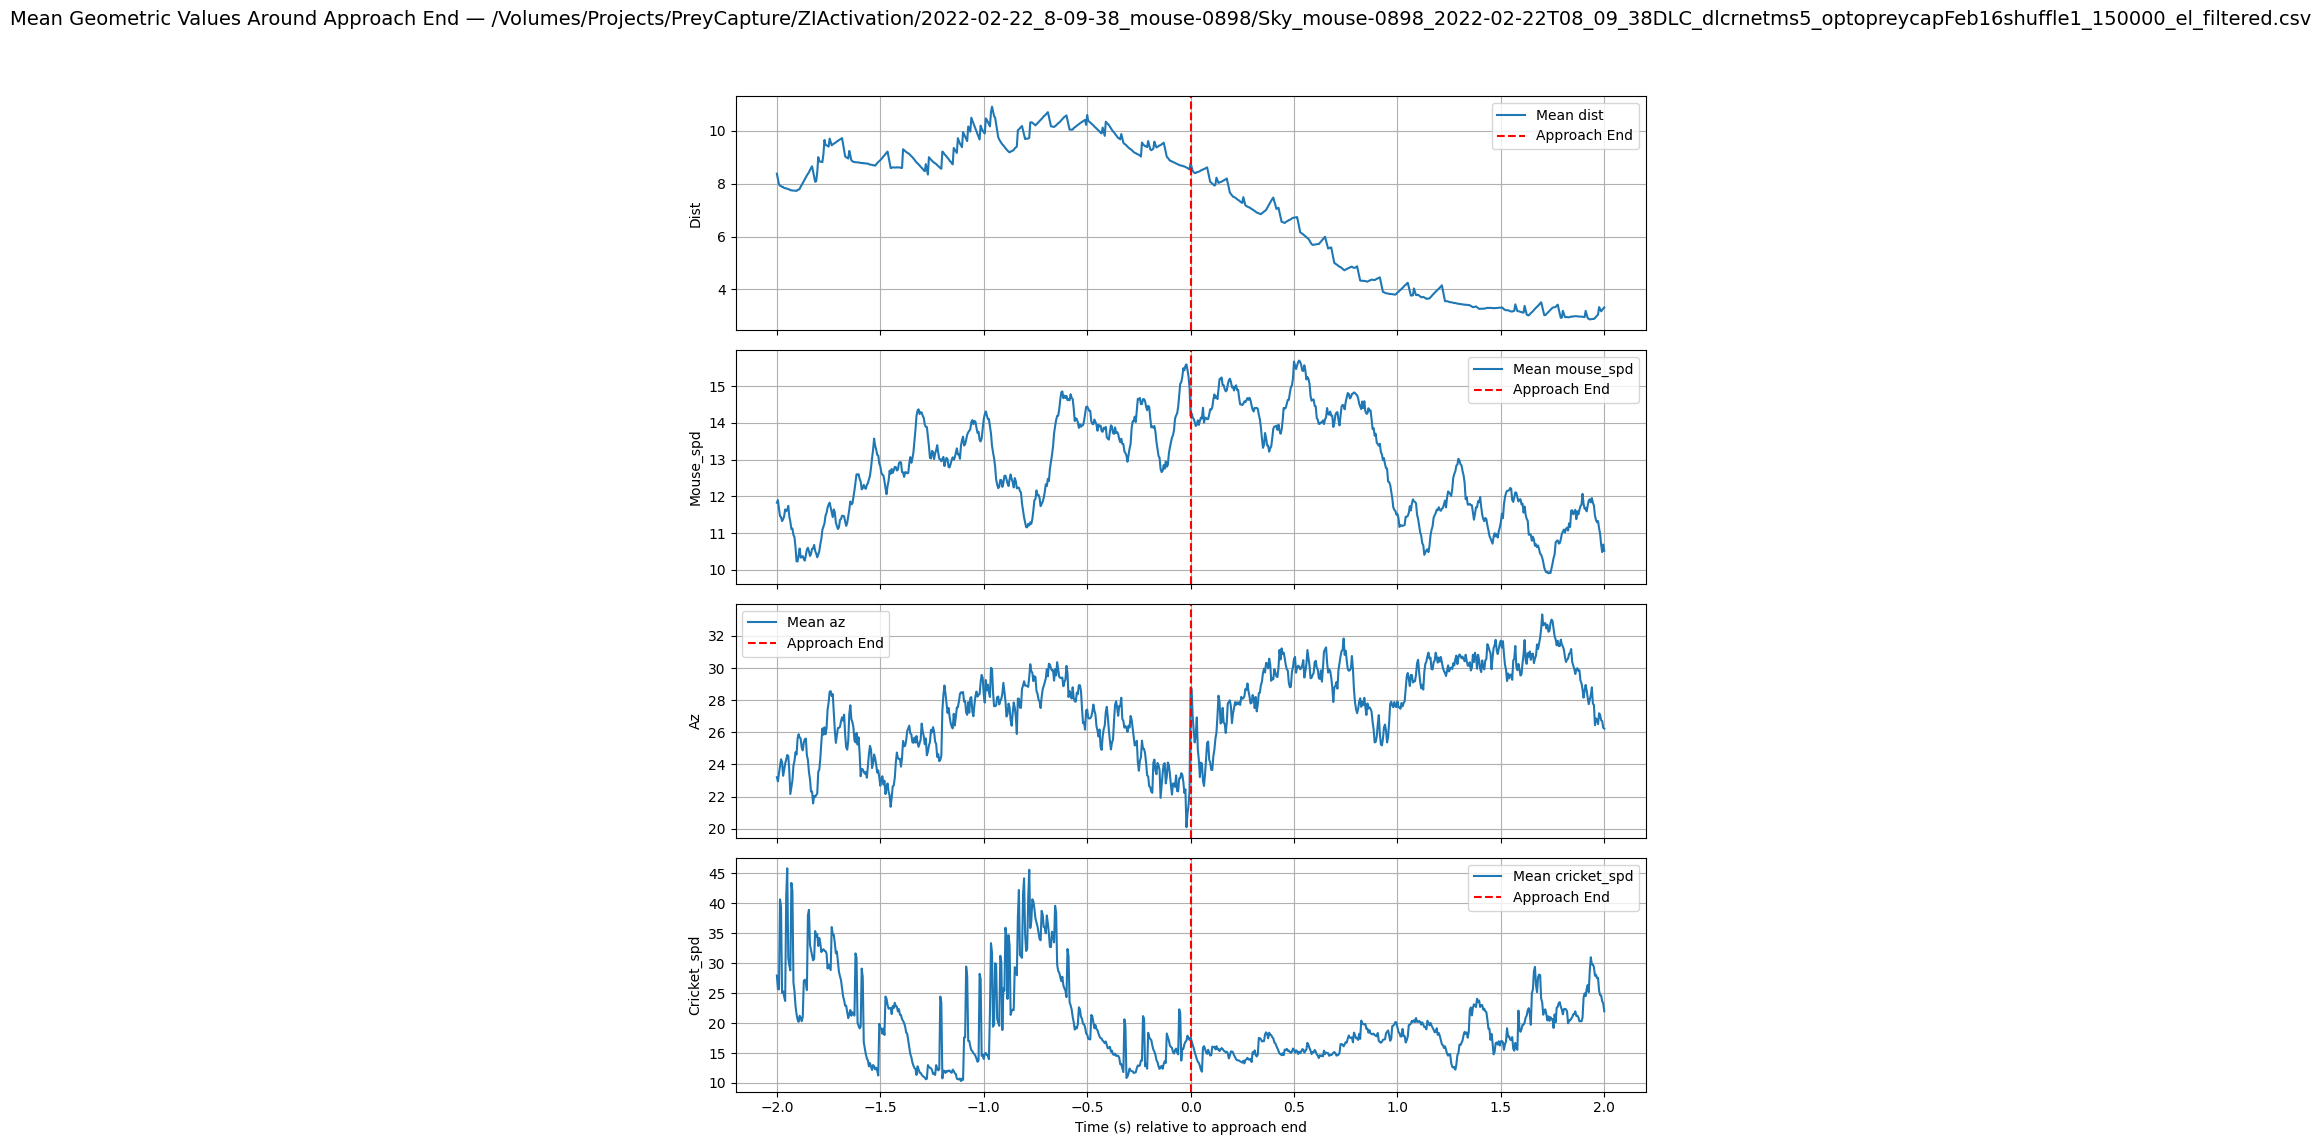

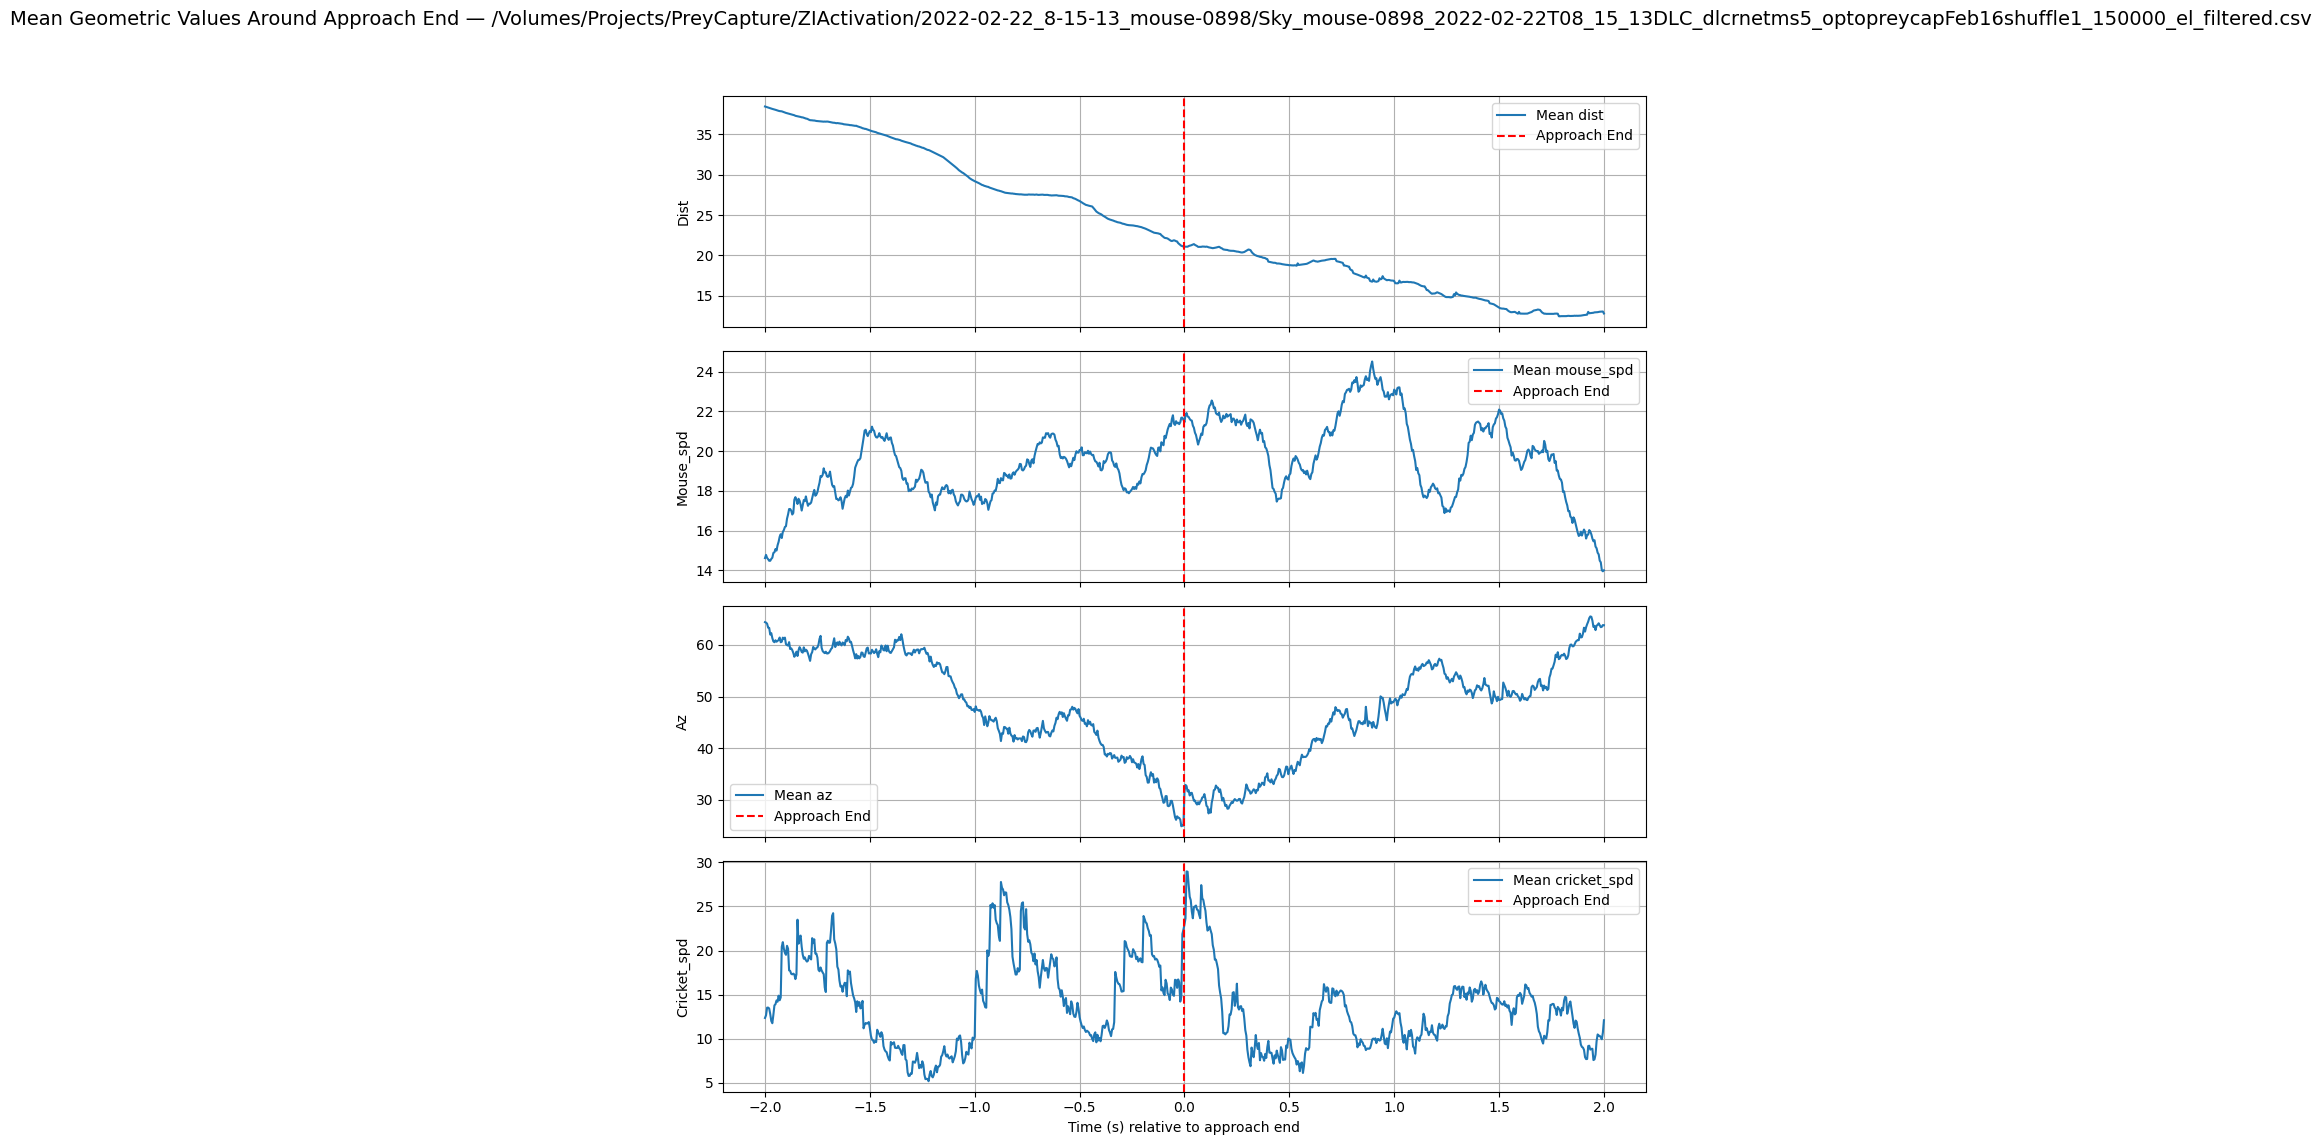

In [9]:

# List of geometry column names
geometry_cols = ['dist_±2s', 'mouse_spd_±2s', 'az_±2s', 'cricket_spd_±2s']
time_axis = np.arange(-window_size, window_size + 1) / 200  # convert frames to seconds

# Plotting for each unique filename
for filename in df_around_approach['filename'].unique():
    subset = df_around_approach[df_around_approach['filename'] == filename]

    fig, axes = plt.subplots(len(geometry_cols), 1, figsize=(10, 3 * len(geometry_cols)), sharex=True)
    fig.suptitle(f"Mean Geometric Values Around Approach End — {filename}", fontsize=14)

    if len(geometry_cols) == 1:
        axes = [axes]  # ensure it's iterable

    for i, col in enumerate(geometry_cols):
        data = np.array(subset[col].tolist())  # shape: (num_approaches, timepoints)
        mean_vals = np.nanmean(data, axis=0)  # ignore NaNs when averaging

        axes[i].plot(time_axis, mean_vals, label=f'Mean {col.replace("_±2s", "")}')
        axes[i].axvline(0, color='r', linestyle='--', label='Approach End')
        axes[i].set_ylabel(col.replace("_±2s", "").capitalize())
        axes[i].legend()
        axes[i].grid(True)

    axes[-1].set_xlabel("Time (s) relative to approach end")
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [18]:
def compute_post_approach_dist_change(dist_slice):
    if dist_slice is None or len(dist_slice) < 800:
        return [np.nan] * 400  # insufficient data
    post_approach = dist_slice[400:800]  # frames 0 to +20 (inclusive), 21 values
    diffs = np.diff(post_approach)  # returns 20 values: diff[i] = val[i+1] - val[i]
    return diffs.tolist()

# Apply to each row
df_around_approach['dist_change_0_to_+400f'] = df_around_approach['dist_±2s'].apply(compute_post_approach_dist_change)


In [19]:
df_around_approach

,filename,approach_end_frame,dist_±2s,mouse_spd_±2s,az_±2s,cricket_spd_±2s,dist_change_0_to_+20f,dist_change_0_to_+400f
0,/Volumes/Projects/PreyCapture/ZIActivation/202...,2435,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[7.0405987758567035, 7.363088420714516, 7.5367...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.1924545080171285, 0.5737431432304163, 0.573...","[0.1924545080171285, 0.5737431432304163, 0.573..."
1,/Volumes/Projects/PreyCapture/ZIActivation/202...,2470,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[14.794910456735922, 15.890214777503706, 16.80...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.6526551555657889, 0.31052355967912604, 0.38...","[0.6526551555657889, 0.31052355967912604, 0.38..."
2,/Volumes/Projects/PreyCapture/ZIActivation/202...,2488,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[13.403145527400042, 13.443265183185616, 14.23...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[-0.156584279128559, -0.30653397435284546, -0....","[-0.156584279128559, -0.30653397435284546, -0...."
3,/Volumes/Projects/PreyCapture/ZIActivation/202...,2543,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[9.597860431518685, 11.348802432188826, 11.919...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[-0.1164091123305866, -0.07574882618365564, -0...","[-0.1164091123305866, -0.07574882618365564, -0..."
4,/Volumes/Projects/PreyCapture/ZIActivation/202...,2555,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.578977316150366, 7.857502199362991, 7.81791...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[-0.04783275972251033, -0.11990010931051742, -...","[-0.04783275972251033, -0.11990010931051742, -..."
...,...,...,...,...,...,...,...,...
123,/Volumes/Projects/PreyCapture/ZIActivation/202...,6124,"[5.684096574969313, 5.660609590348505, 5.55460...","[45.86471177441129, 45.45546084173137, 41.4865...","[39.051824536281806, 38.70730300102923, 24.049...","[38.43899369827684, 36.58152552603436, 32.8874...","[-0.015088458331284027, -0.015088458331284027,...","[-0.015088458331284027, -0.015088458331284027,..."
124,/Volumes/Projects/PreyCapture/ZIActivation/202...,7465,"[17.62911221746935, 17.595489202648857, 17.561...","[5.857763643214623, 5.420741183201145, 5.30982...","[137.21767853588403, 136.94679757987024, 136.6...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[-0.0336230148204919, -0.0336230148204919, -0....","[-0.0336230148204919, -0.0336230148204919, -0...."
125,/Volumes/Projects/PreyCapture/ZIActivation/202...,7501,"[16.41868368393163, 16.385060669111137, 16.351...","[0.17026146461768552, 0.5080406309718002, 0.95...","[127.46596411938687, 127.19508316337303, 126.9...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[-0.0336230148204919, -0.0336230148204919, -0....","[-0.0336230148204919, -0.0336230148204919, -0...."
126,/Volumes/Projects/PreyCapture/ZIActivation/202...,7579,"[13.79608852793324, 13.762465513112746, 13.728...","[0.7639596339552721, 0.8571181419643215, 0.671...","[106.33724955030961, 106.06636859429578, 105.7...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.012612314974442373, 0.012612314974442818, 0...","[0.012612314974442373, 0.012612314974442818, 0..."


In [22]:
22*200

4400

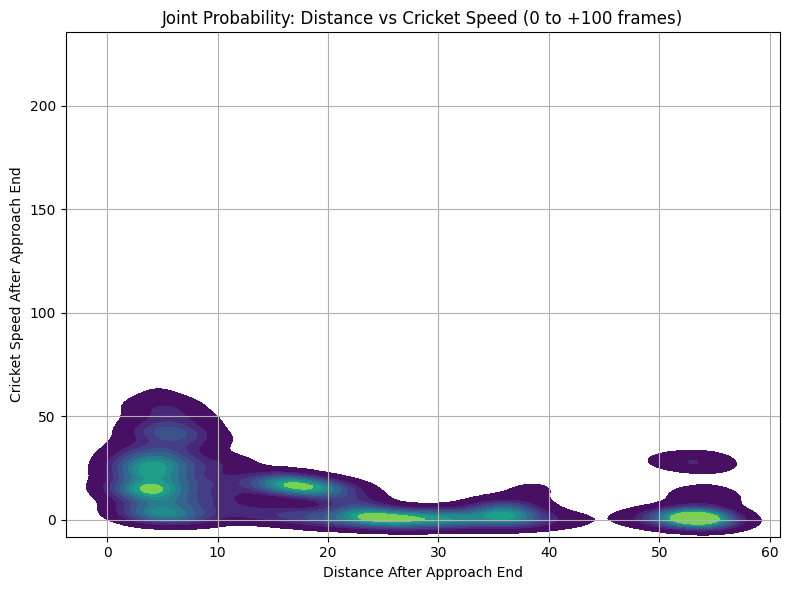

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Collect all post-approach dist and cricket_spd values
post_dist = []
post_cricket_spd = []

for _, row in df_around_approach.iterrows():
    dist = row['dist_±2s']
    cricket_spd = row['cricket_spd_±2s']
    
    if dist is not None and cricket_spd is not None and len(dist) >= 501 and len(cricket_spd) >= 501:
        post_dist.extend(dist[400:501])
        post_cricket_spd.extend(cricket_spd[400:501])

# Convert to arrays
post_dist = np.array(post_dist)
post_cricket_spd = np.array(post_cricket_spd)

# Drop NaNs
mask = ~np.isnan(post_dist) & ~np.isnan(post_cricket_spd)
x = post_dist[mask]
y = post_cricket_spd[mask]


# Plot joint distribution
plt.figure(figsize=(8, 6))
sns.kdeplot(x=x, y=y, fill=True, cmap="viridis", bw_adjust=0.5, thresh=0.05)
plt.xlabel("Distance After Approach End")
plt.ylabel("Cricket Speed After Approach End")
plt.title("Joint Probability: Distance vs Cricket Speed (0 to +100 frames)")
plt.grid(True)
plt.tight_layout()
plt.show()


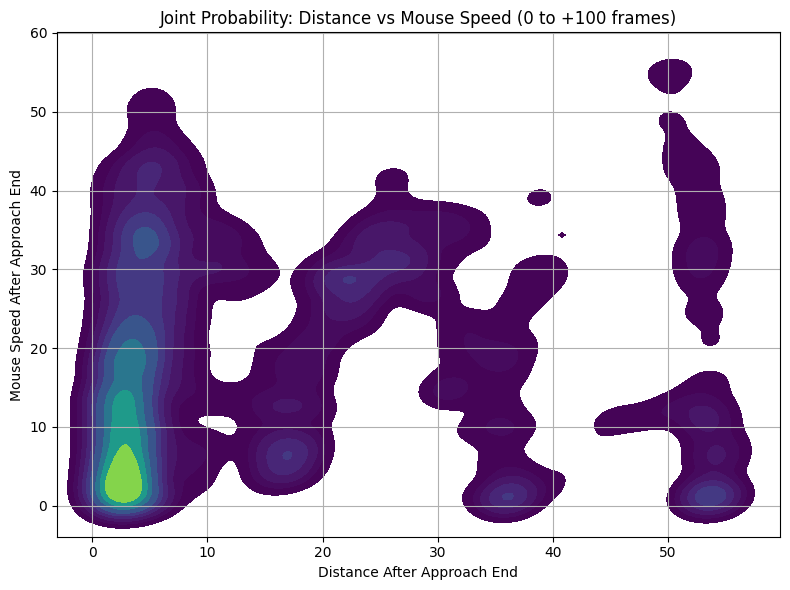

In [15]:

# Collect all post-approach dist and cricket_spd values
post_dist = []
post_mouse_spd = []

for _, row in df_around_approach.iterrows():
    dist = row['dist_±2s']
    mouse_spd = row['mouse_spd_±2s']
    
    if dist is not None and mouse_spd is not None and len(dist) >= 501 and len(mouse_spd) >= 501:
        post_dist.extend(dist[400:501])
        post_mouse_spd.extend(mouse_spd[400:501])

# Convert to arrays
post_dist = np.array(post_dist)
post_mouse_spd = np.array(post_mouse_spd)

# Drop NaNs
mask = ~np.isnan(post_dist) & ~np.isnan(post_mouse_spd)
x = post_dist[mask]
y = post_mouse_spd[mask]


# Plot joint distribution
plt.figure(figsize=(8, 6))
sns.kdeplot(x=x, y=y, fill=True, cmap="viridis", bw_adjust=0.5, thresh=0.05)
plt.xlabel("Distance After Approach End")
plt.ylabel("Mouse Speed After Approach End")
plt.title("Joint Probability: Distance vs Mouse Speed (0 to +100 frames)")
plt.grid(True)
plt.tight_layout()
plt.show()


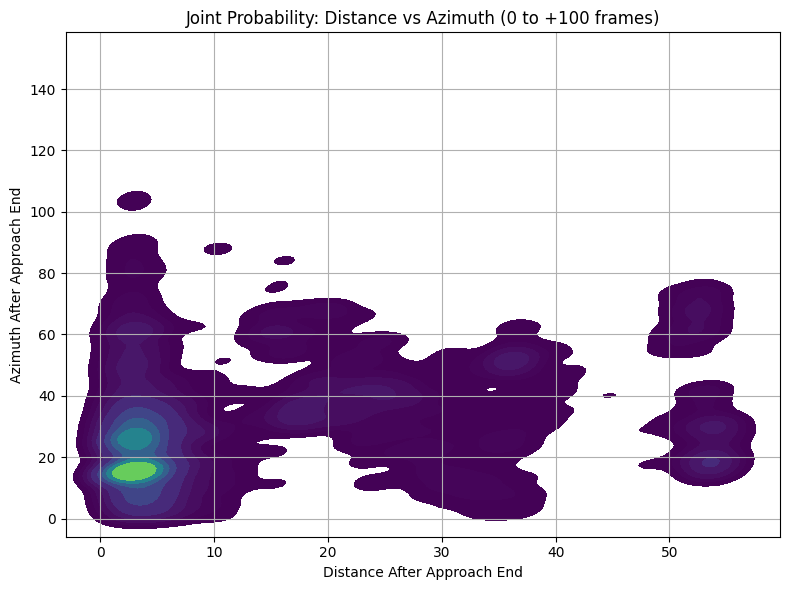

In [16]:


# Collect all post-approach dist and cricket_spd values
post_dist = []
post_az = []

for _, row in df_around_approach.iterrows():
    dist = row['dist_±2s']
    az = row['az_±2s']
    
    if dist is not None and cricket_spd is not None and len(dist) >= 501 and len(az) >= 501:
        post_dist.extend(dist[400:501])
        post_az.extend(az[400:501])

# Convert to arrays
post_dist = np.array(post_dist)
post_az = np.array(post_az)

# Drop NaNs
mask = ~np.isnan(post_dist) & ~np.isnan(post_az)
x = post_dist[mask]
y = post_az[mask]


# Plot joint distribution
plt.figure(figsize=(8, 6))
sns.kdeplot(x=x, y=y, fill=True, cmap="viridis", bw_adjust=0.5, thresh=0.05)
plt.xlabel("Distance After Approach End")
plt.ylabel("Azimuth After Approach End")
plt.title("Joint Probability: Distance vs Azimuth (0 to +100 frames)")
plt.grid(True)
plt.tight_layout()
plt.show()


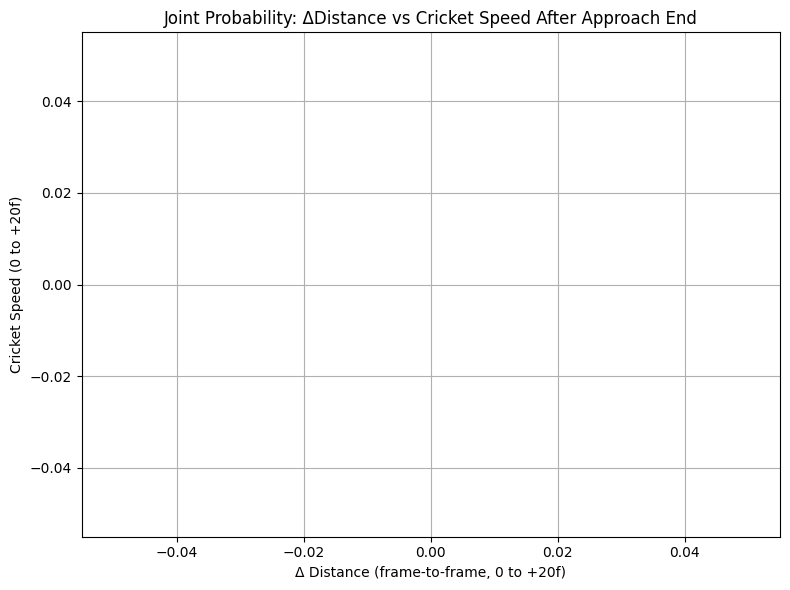

In [21]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

delta_dist_all = []
cricket_spd_all = []

for _, row in df_around_approach.iterrows():
    delta_dist = row['dist_change_0_to_+400f']
    cricket_spd = row['cricket_spd_±2s']

    # Validate data
    if delta_dist is not None and cricket_spd is not None:
        if len(delta_dist) == 20 and len(cricket_spd) >= 421:
            cricket_spd_post = cricket_spd[401:421]  # frames +1 to +20

            # Append only non-NaN pairs
            for d, s in zip(delta_dist, cricket_spd_post):
                if not (np.isnan(d) or np.isnan(s)):
                    delta_dist_all.append(d)
                    cricket_spd_all.append(s)

# Convert to arrays
delta_dist_all = np.array(delta_dist_all)
cricket_spd_all = np.array(cricket_spd_all)

# Plot joint distribution (KDE)
plt.figure(figsize=(8, 6))
sns.kdeplot(
    x=delta_dist_all,
    y=cricket_spd_all,
    fill=True,
    cmap="viridis",
    bw_adjust=0.7,
    thresh=0.05
)
plt.xlabel("Δ Distance (frame-to-frame, 0 to +20f)")
plt.ylabel("Cricket Speed (0 to +20f)")
plt.title("Joint Probability: ΔDistance vs Cricket Speed After Approach End")
plt.grid(True)
plt.tight_layout()
plt.show()


(0.0, 5.0)

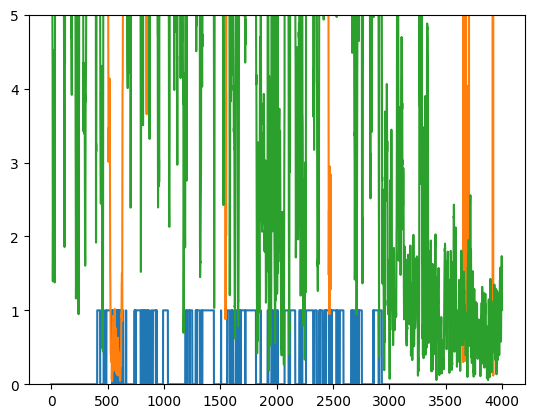

In [169]:
plt.plot(approaches_df['approach_bool'].iloc[10][2000:6000])
# plt.plot(cleaned_conds_keep['dist'].iloc[10][2000:6000])
# plt.plot(cleaned_conds_keep['az'].iloc[10][2000:6000])
plt.plot(cleaned_conds_keep['cricket_spd'].iloc[10][2000:6000])
plt.plot(cleaned_conds_keep['mouse_spd'].iloc[10][2000:6000])
plt.ylim(0,5)

### quantify cricket "overrruns", mouse runs past the cricket when it stops, then look at behavior following these

### simplest option, just look at distribution of geos during pursuit periods

✅ Merge complete. Columns: ['filename', 'folder_path', 'condition', 'laser_value', 'dist', 'cricket_spd', 'mouse_spd', 'az', 'captureT', 'cricketdrop', 'captureframe', 'freqapproach', 'timetoapproach', 'prob_inter', 'prob_capture', 'timetointercept', 'interceptframe', 'c_length', 'capduration', 'trials_to_drop', 'corrected_timetointercept', 'corrected_capduration', 'timestamps', 'approach_bool']

🧪 Condition: 1, Laser: 0
  → Trials found: 225
  ✅ Extracted 309090 valid geometry values

🧪 Condition: 1, Laser: 1
  → Trials found: 227
  ✅ Extracted 318436 valid geometry values

🧪 Condition: 2, Laser: 0
  → Trials found: 252
  ✅ Extracted 332261 valid geometry values

🧪 Condition: 2, Laser: 1
  → Trials found: 254
  ✅ Extracted 305539 valid geometry values


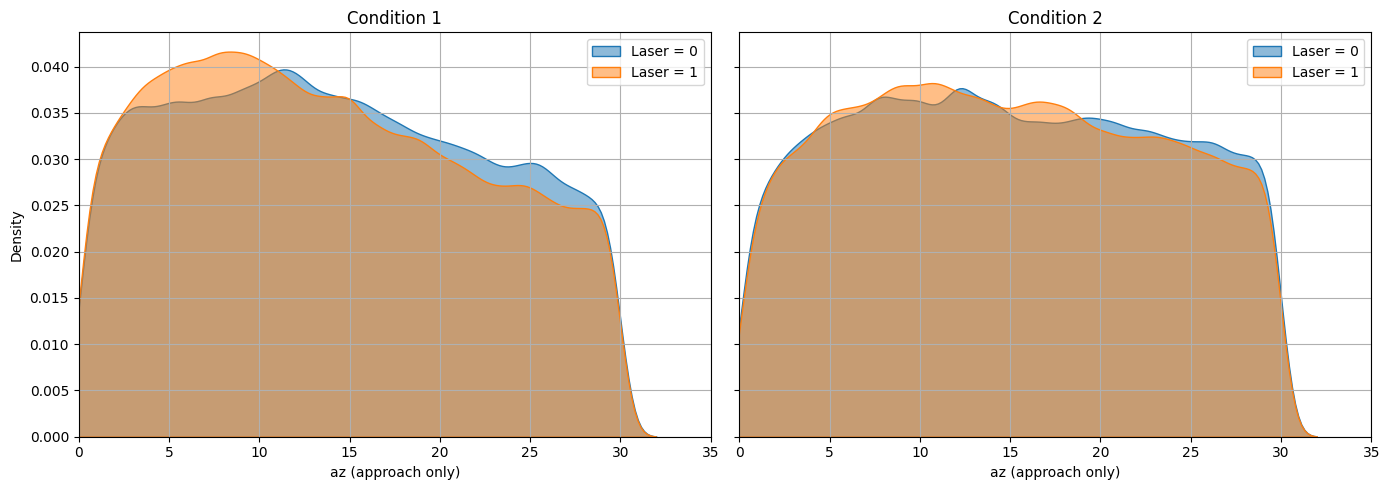

In [110]:
# step 1: read in approach periods and geos 
# step 2: align geos and approaches arrays
# step 2: plot distributions for az and range but only for the frames where approach=1


# === SETTINGS ===
geometry_column = 'az'         # Replace with 'c_length', 'mouse_spd', etc., if needed
conditions = ['1', '2']        # Must match type in your DataFrame — here as strings
laser_values = [0, 1]          # Laser ON vs OFF

# === SANITY CHECK ===
if 'approach_bool' not in approaches_df.columns:
    raise KeyError("❌ 'approach_bool' column not found in approaches_df")

# === PREPROCESSING ===

# Drop approach_bool from geometry df to avoid duplicate columns
if 'approach_bool' in cleaned_conds_keep.columns:
    cleaned_conds_keep = cleaned_conds_keep.drop(columns=['approach_bool'])

df_geom = cleaned_conds_keep.copy()
df_geom['condition'] = df_geom['condition'].astype(str)

df = df_geom.merge(
    approaches_df[['filename', 'approach_bool']],
    on='filename',
    how='inner',
    validate='one_to_one'
)

print("✅ Merge complete. Columns:", df.columns.tolist())

# === FUNCTION: Extract geometry values during approach ===
import ast

def extract_approach_geometries(df, condition, laser_value, geometry_column):
    subset = df[(df['condition'] == condition) & (df['laser_value'] == laser_value)]
    all_values = []

    print(f"\n🧪 Condition: {condition}, Laser: {laser_value}")
    print(f"  → Trials found: {len(subset)}")

    for idx, row in subset.iterrows():
        geometry = row[geometry_column]
        approach = row['approach_bool']

        # Accept lists or numpy arrays
        if isinstance(geometry, (list, np.ndarray)) and isinstance(approach, (list, np.ndarray)):
            if len(geometry) != len(approach):
                print(f"  ⚠️ Skipping trial {idx} — length mismatch ({len(geometry)} vs {len(approach)})")
                continue

            try:
                geom_arr = np.array(geometry, dtype=np.float32)
                appr_arr = np.array(approach, dtype=bool)
                valid_mask = appr_arr & ~np.isnan(geom_arr)
                valid = geom_arr[valid_mask]
                all_values.extend(valid)
            except Exception as e:
                print(f"  ⚠️ Error in trial {idx}: {e}")

        else:
            print(f"  ⚠️ Skipping trial {idx} — invalid data types (geometry type: {type(geometry)}, approach type: {type(approach)})")

    print(f"  ✅ Extracted {len(all_values)} valid geometry values")
    return all_values



# === PLOTTING ===

fig, axs = plt.subplots(1, len(conditions), figsize=(14, 5), sharey=True)

for i, cond in enumerate(conditions):
    ax = axs[i]
    for lv in laser_values:
        values = extract_approach_geometries(df, cond, lv, geometry_column)
        if len(values) > 0:
            sns.kdeplot(values, label=f'Laser = {lv}', ax=ax, fill=True, alpha=0.5)
        else:
            print(f"⚠️ No values to plot for condition={cond}, laser={lv}")

    ax.set_title(f'Condition {cond}')
    ax.set_xlabel(f'{geometry_column} (approach only)')
    ax.set_ylabel('Density')
    ax.set_xlim(0,35)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()



### another simple option, look first at the mean/ median length of approach (pursuit) bouts by condition
##### could then also use this to look at second order stuff like are the angles or ranges different during longer/ shorter appproaches

In [ ]:
# step 1: read in the approach periods that were outputted by previous function
# step 2: calculate the length of each pursuit 
# step 3: compare these between each condition
# step 4: also maybe plot distrib of az and range with respect to pursuit length

### try just looking at total distance traveled across the whole trial

In [2]:
def total_distance_from_xy_array(xy_array):
    if xy_array.shape[0] != 2:
        raise ValueError("Input should have shape (2, N), with first row x and second row y")

    # Reshape to (N, 2) where each row is [x, y]
    positions = xy_array.T  # Now shape is (N, 2)

    # Remove NaNs (in case there are dropped frames)
    positions = positions[~np.isnan(positions).any(axis=1)]

    # Compute total distance
    diffs = np.diff(positions, axis=0)
    step_distances = np.linalg.norm(diffs, axis=1)
    return np.sum(step_distances)

from scipy.signal import savgol_filter

def smooth_xy_array(xy_array, window_length=11, polyorder=2):
    """
    Smooths a 2xN array of x and y positions using Savitzky-Golay filter.
    - window_length must be odd and >= polyorder + 2
    """
    if xy_array.shape[0] != 2:
        raise ValueError("Input must be a 2xN array of x and y coordinates.")

    # Handle short arrays
    if xy_array.shape[1] < window_length:
        return xy_array  # Not enough data to smooth

    smoothed_x = savgol_filter(xy_array[0], window_length, polyorder)
    smoothed_y = savgol_filter(xy_array[1], window_length, polyorder)

    return np.vstack([smoothed_x, smoothed_y])


from scipy.stats import mannwhitneyu

def plot_distance_distributions_by_condition(df):
    conditions = sorted(df['condition'].unique())
    distance_columns = [
        ('mouse_total_distance', 'Total Distance'),
        ('preycap_distance_traveled', 'Prey Capture Distance')
    ]

    for distance_column, title_label in distance_columns:
        for cond in conditions:
            plt.figure(figsize=(8, 6))
            subset = df[df['condition'] == cond]

            group_stats = {}
            for laser_val, color, label in zip([0, 1], ['#929591', '#2976bb'], ['Laser OFF', 'Laser ON']):
                laser_subset = subset[subset['laser_value'] == laser_val]
                valid_data = laser_subset[distance_column].dropna()

                if len(valid_data) > 1:
                    sns.kdeplot(
                        x=valid_data,
                        fill=True,
                        alpha=0.5,
                        linewidth=2,
                        label=label,
                        color=color
                    )
                    mean = valid_data.mean()
                    std = valid_data.std()

                    # Add vertical mean line
                    plt.axvline(mean, color=color, linestyle='--', linewidth=1.5)

                    # Store stats for p-value test
                    group_stats[laser_val] = valid_data

                    # Add text annotation
                    plt.text(
                        mean,
                        plt.ylim()[1]*0.9 if laser_val == 0 else plt.ylim()[1]*0.8,
                        f"Mean = {mean:.1f} ± {std:.1f}",
                        color=color,
                        ha='center',
                        fontsize=10,
                        bbox=dict(facecolor='white', edgecolor=color, alpha=0.6)
                    )
                else:
                    print(f"⚠️ Not enough valid data for condition {cond}, laser {laser_val}, distance: {distance_column} — skipping KDE")

            # Optional: statistical test between laser=0 and laser=1
            if 0 in group_stats and 1 in group_stats:
                stat, pval = mannwhitneyu(group_stats[0], group_stats[1], alternative='two-sided')
                plt.text(
                    0.95, 0.95,
                    f"Mann-Whitney U p = {pval:.3f}",
                    transform=plt.gca().transAxes,
                    ha='right',
                    va='bottom',
                    fontsize=11,
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='black')
                )

            plt.title(f"{title_label} — Condition {cond}")
            plt.xlabel(f"{title_label} (units)")
            plt.ylabel("Density")
            plt.legend()
            plt.tight_layout()
            sns.despine()
            plt.show()


        

In [4]:
FPS = 200
max_frames = int(125 * FPS)

results = []
cols_to_keep = ['filename', 'condition', 'laser_value', 'captureT', 'cricketdrop', 'captureframe']

for idx, row in cleaned_conds_keep[cols_to_keep].iterrows():
    filename = row['filename']
    capture_time = row['captureT']
    drop_frame = row['cricketdrop']
    capture_frame = row['captureframe']

    try:
        mouse_xy, cricket_p, cricket_xy, rear_xy, lear_xy, spine_xy, cricket_front, cricket_back = preycap.extract_points(
            filename, ['Rear', 'Lear', 'anteriorC', 'posteriorC', 'spine']
        )

        if pd.isna(capture_time) or capture_time > 125:
            mouse_xy = mouse_xy[:, :max_frames]

        smoothed_mouse_xy = smooth_xy_array(mouse_xy)
        total_mouse_distance = total_distance_from_xy_array(smoothed_mouse_xy)

        preycap_distance = np.nan
        capture_duration = np.nan     # <--- NEW

        if pd.notna(drop_frame) and pd.notna(capture_frame):
            drop_frame = int(drop_frame)
            capture_frame = int(capture_frame)

            if 0 <= drop_frame < capture_frame <= mouse_xy.shape[1]:
                # Distance during capture
                segment = mouse_xy[:, drop_frame:capture_frame]
                segment_smoothed = smooth_xy_array(segment)
                preycap_distance = total_distance_from_xy_array(segment_smoothed)

                # Capture duration in seconds
                capture_duration = (capture_frame - drop_frame) / FPS

        result_row = {
            'filename': filename,
            'condition': row['condition'],
            'laser_value': row['laser_value'],
            'captureT': capture_time,
            'mouse_total_distance': total_mouse_distance,
            'preycap_distance_traveled': preycap_distance,
            'capture_duration_s': capture_duration    # <--- NEW
        }
        results.append(result_row)

    except Exception as e:
        print(f"⚠️ Failed on {filename}: {e}")
        continue

distance_df = pd.DataFrame(results)
print(distance_df.head())


⚠️ Failed on /Volumes/Projects/PreyCapture/ZIActivation/2022-07-26_9-07-04_mouse-0893/Sky_mouse-0893_2022-07-26T09_07_04DLC_dlcrnetms5_optopreycapFeb16shuffle1_150000_el_filtered.csv: [Errno 60] Operation timed out
⚠️ Failed on /Volumes/Projects/PreyCapture/ZIActivation/2022-07-26_9-09-03_mouse-0893/Sky_mouse-0893_2022-07-26T09_09_03DLC_dlcrnetms5_optopreycapFeb16shuffle1_150000_el_filtered.csv: [Errno 60] Operation timed out: '/Volumes/Projects/PreyCapture/ZIActivation/2022-07-26_9-09-03_mouse-0893/Sky_mouse-0893_2022-07-26T09_09_03DLC_dlcrnetms5_optopreycapFeb16shuffle1_150000_el_filtered.csv'
⚠️ Failed on /Volumes/Projects/PreyCapture/ZIActivation/2022-07-26_9-11-01_mouse-0893/Sky_mouse-0893_2022-07-26T09_11_01DLC_dlcrnetms5_optopreycapFeb16shuffle1_150000_el_filtered.csv: [Errno 60] Operation timed out: '/Volumes/Projects/PreyCapture/ZIActivation/2022-07-26_9-11-01_mouse-0893/Sky_mouse-0893_2022-07-26T09_11_01DLC_dlcrnetms5_optopreycapFeb16shuffle1_150000_el_filtered.csv'
⚠️ Failed

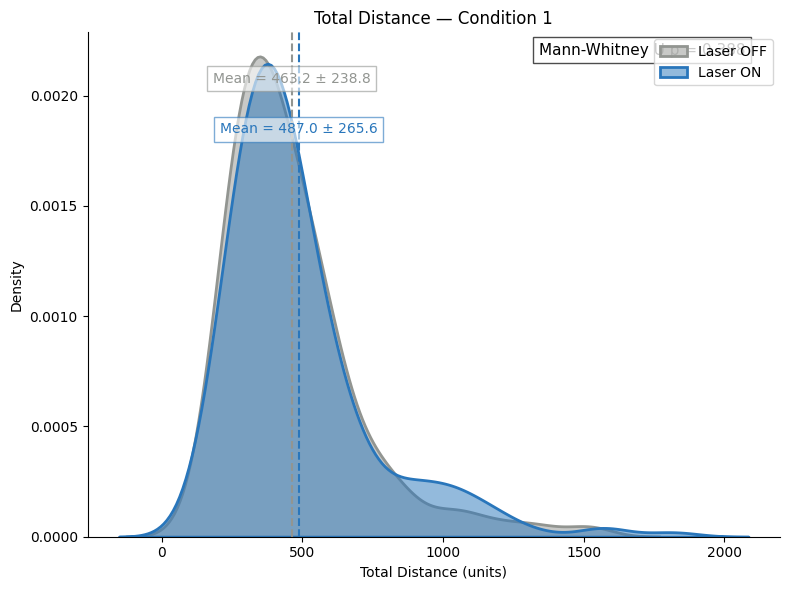

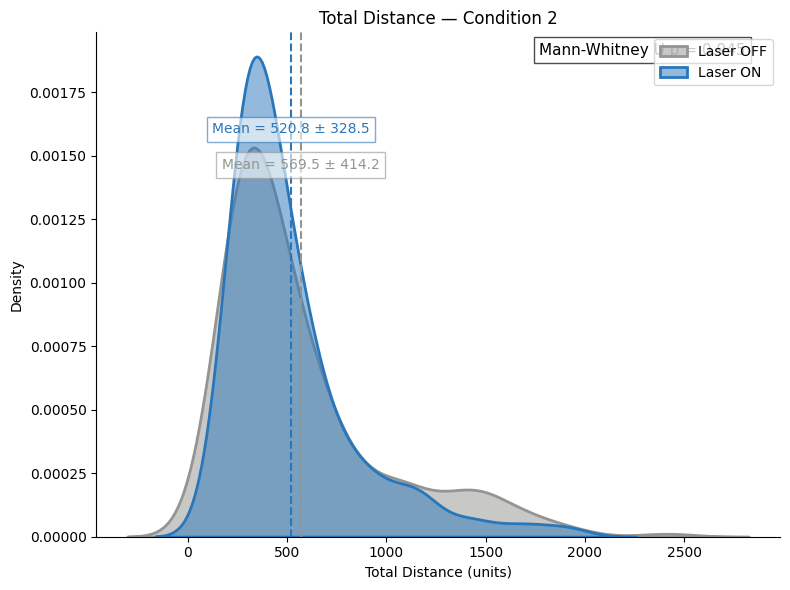

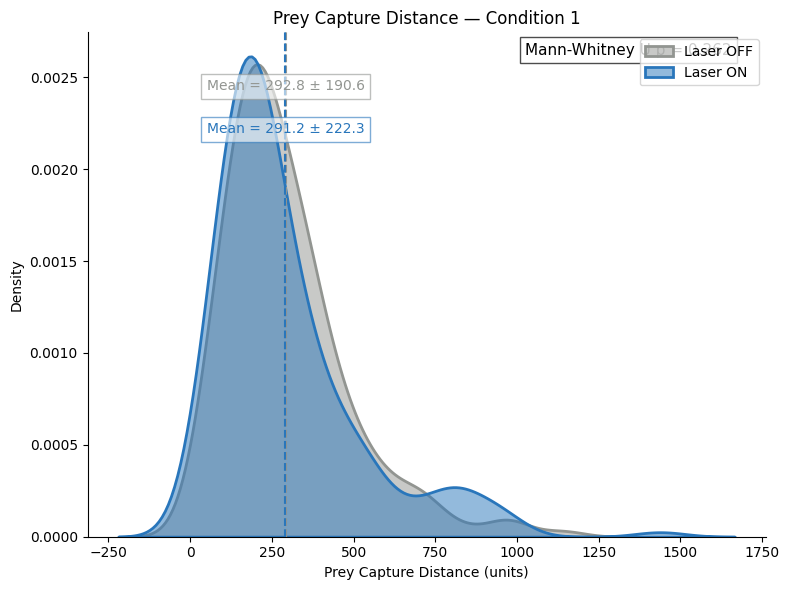

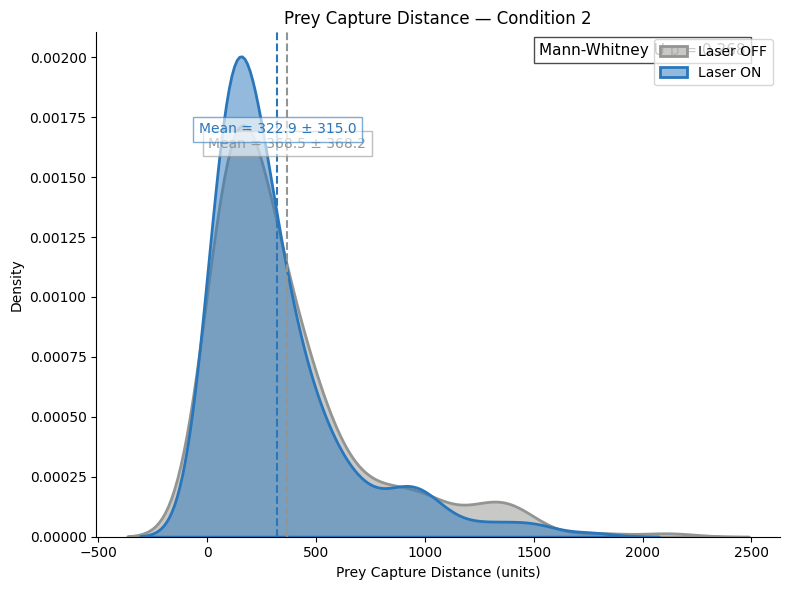

In [146]:
plot_distance_distributions_by_condition(distance_df)

### similar logic, find proportion of trial spent stationary, distance shifts maybe aren't as extreme in the light because they are moving less overall